In [1]:
import numpy as np
import matplotlib.pyplot as plt

import sys
sys.path.append("..")


from trips.test_problems.Tomography import Tomography
import astra

import jlinops


from rsolvers import RIASGKS, RMMGKS

In [2]:
# Define an object of the class Tomogrpahy
Tomo = Tomography ()
# Specify the dimensions of the phantom and the number of angels
nx = 150
ny = 150
views = 100
# Define the true solution throught the function gen_true ().
( x_true , nx , ny ) = Tomo.gen_true( test_problem = "grains", nx = nx , ny = ny)
# Define the forward operator
A = Tomo.forward_Op( nx , ny , views )
# Generate the data
(A , b_true , p , q , AforMatrixOperation ) = Tomo.gen_data( x_true , nx , ny , views )
# Add noise in the true simulated sinogram b_true
(b , delta ) = Tomo.add_noise( b_true = b_true , opt = "Gaussian", noise_level= 0.001)

settings
no crime


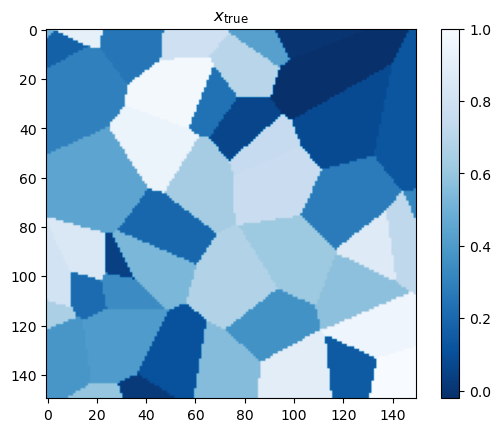

In [3]:
plt.imshow(x_true.reshape((nx,ny)), cmap="Blues_r")
plt.title("$x_{\\text{true}}$")
plt.colorbar()
plt.show()

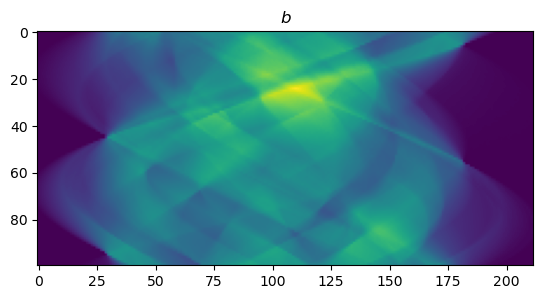

In [4]:
plt.imshow(b)
plt.title("$b$")
plt.show()

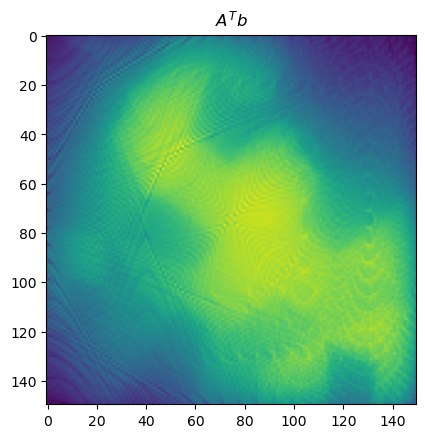

In [5]:
plt.imshow((A.T @ b.flatten()).reshape((nx,ny)))
plt.title("$A^T b$")
plt.show()

In [7]:
L = jlinops.Neumann2D((nx, ny)) # gradient regularization
#L = jlinops.IdentityOperator((M*N, M*N)) # identity regularization

rmmgks_solver = RIASGKS(A, L, b.flatten(), noise_var=(delta**2 / len(b.flatten()) ) )
data = rmmgks_solver.solve(n_iter=100, init_dim=10, kmin=10, kmax=25, hyperpr_r=1.0, hyperpr_beta=1.5 + 1e-3, x_true=x_true, regparam="dp3", eta=1.01)
#data = rmmgks_solver.solve(n_iter=100, init_dim=10, kmin=10, kmax=25, hyperpr_r=-1.0, hyperpr_beta=1.0, x_true=x_true, regparam="dp", eta=np.sqrt(1.01))

/Users/jonathanlindbloom/miniforge3/envs/jlinops/lib/python3.11/site-packages/pylops/linearoperator.py:1280: RuntimeWarning: overflow encountered in multiply
  return np.conj(self.args[1]) * self.args[0].rmatvec(x)


/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems/../regparam_selection.py:305: RuntimeWarning: overflow encountered in scalar power
  term1 = - (2/(beta**2))*(np.linalg.norm(Lxbeta)**2)
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems/../regparam_selection.py:309: RuntimeWarning: overflow encountered in scalar power
  term2 = (2/(beta**2))*np.dot(QinvLtLxbeta, AtAxbeta )
/Users/jonathanlindbloom/Github/IRLS_prec_GSBL/test_problems/../regparam_selection.py:290: RuntimeWarning: invalid value encountered in scalar divide
  mu = beta + phi_prime/(2*phi_prime_prime)


 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value
 ** On entry to DLASCL parameter number  4 had an illegal value


LinAlgError: SVD did not converge in Linear Least Squares

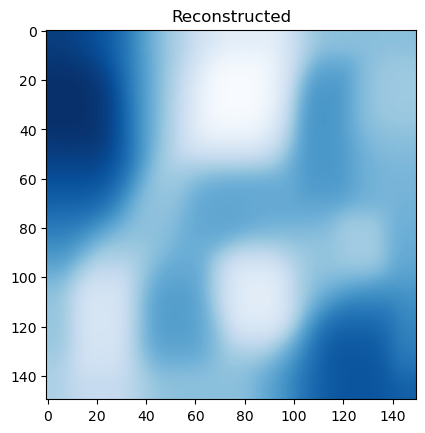

In [33]:
plt.imshow(data["x"].reshape((nx,ny)), cmap="Blues_r")
plt.title("Reconstructed")
plt.show()

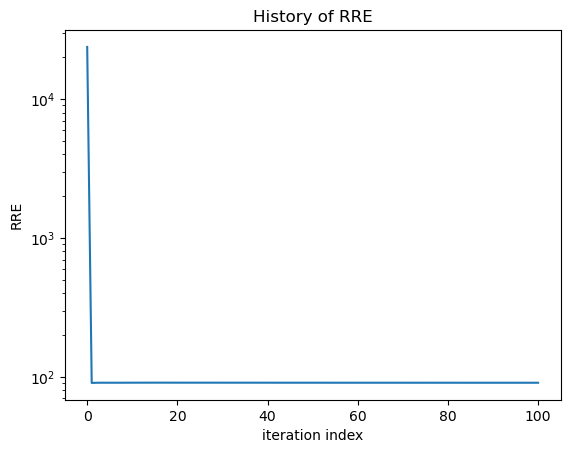

In [34]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

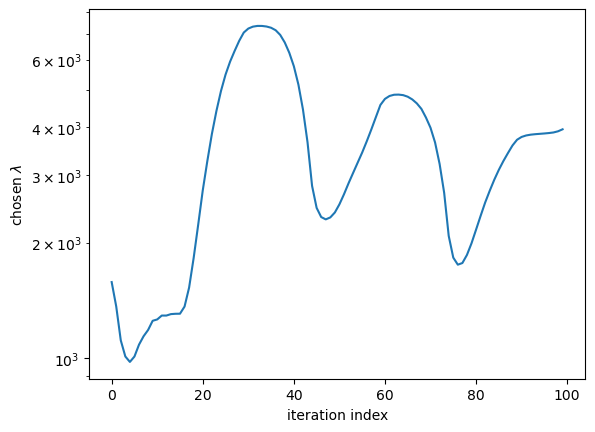

In [35]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

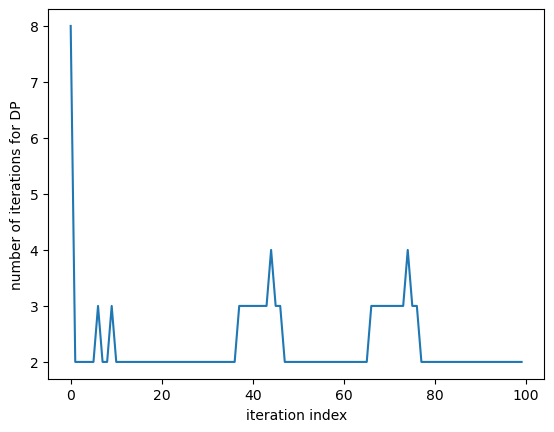

In [36]:
plt.plot(data["dp_cubic_n_iters"])
plt.xlabel("iteration index")
plt.ylabel("number of iterations for DP")
plt.show()

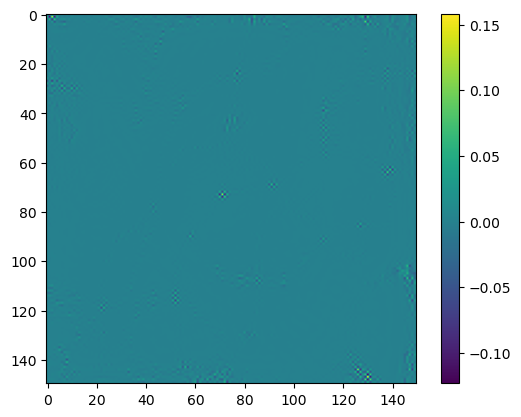

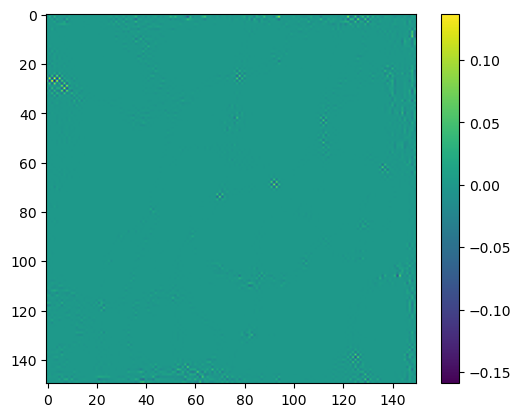

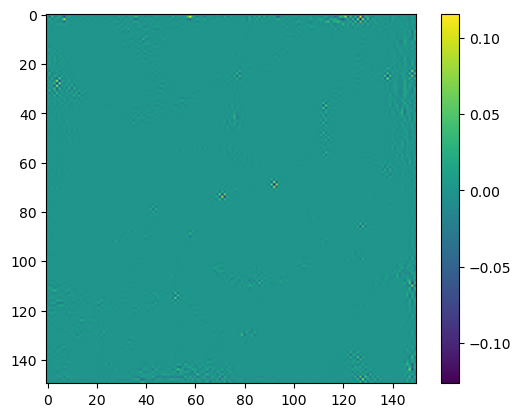

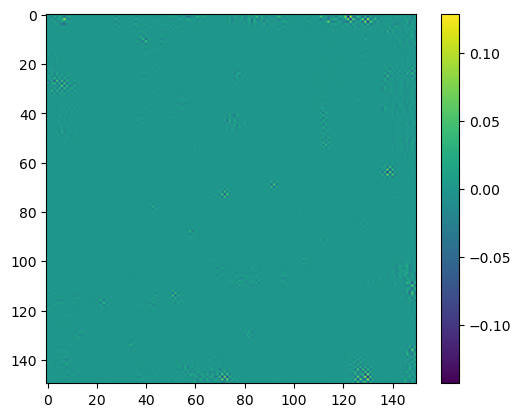

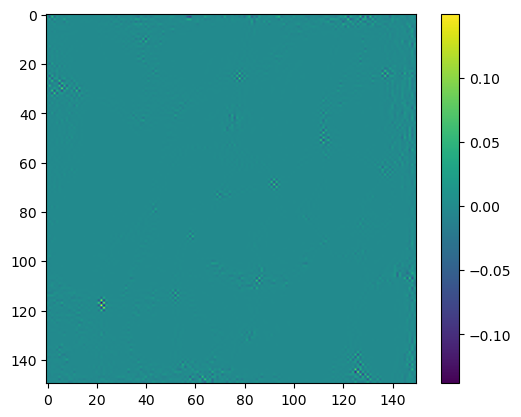

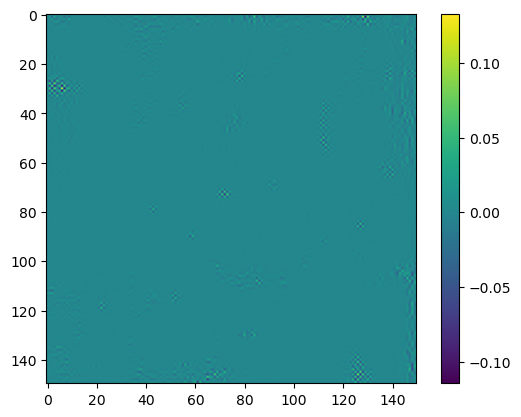

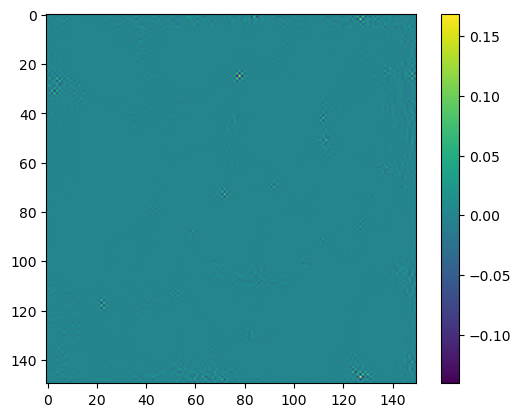

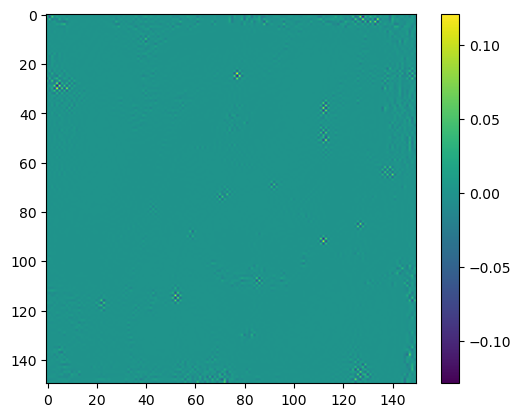

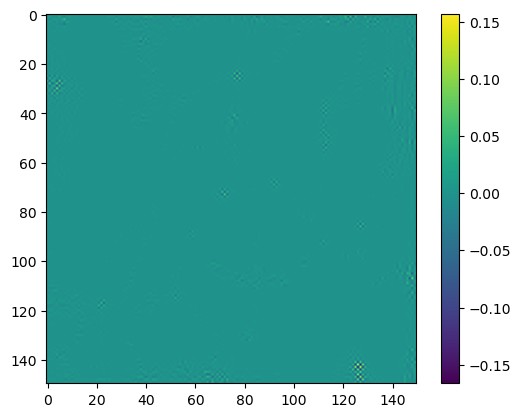

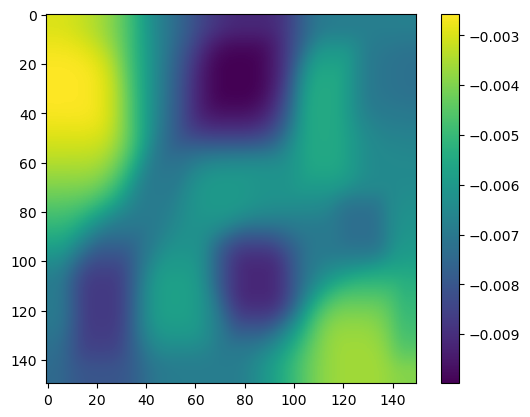

In [37]:
for j in range(10):
    tmp = data["V"][:,j].reshape((nx,ny))
    plt.figure()
    plt.imshow(tmp)
    plt.colorbar()